In [1]:
import numpy as np
import networkx as nx
from pympler import asizeof


In [2]:


# N = 10000
# M = 3*N
# edges = np.random.randint(0,N, size = (M,2)).tolist()
# # obiekt  = np.zeros((N,N),dtype = np.uint8)
# # for i,j in edges:
# #     obiekt[i,j] = obiekt[j,i] =1 

# # print(f"{asizeof.asizeof(obiekt/1e6)} MB")

# adj = [[] for _ in range(N)]
# for i,j in edges:
#     adj[i].append(j)
#     adj[j].append(i)


# indicies, indptr = [],[0]    
# for neighbours in adj:
#     indicies.extend(neighbours)
#     indptr.append(len(indicies))
# indicies = np.array(indicies,dtype=np.int32)
# indptr = np.array(indptr,dtype=np.int32)


# print(f"{asizeof.asizeof(indicies,indptr)/1e6} MB")


# import matplotlib.pyplot as plt

# Ns= [100,1000,10000]
# for N in Ns:
#     M = 3*N
#     edges = np.random.randint(0,N, size = (M,2)).tolist()
#     G  = nx.from_edgelist(edges)
#     # nx.draw(G,with_labels=True,node_color="lightblue")
#     # plt.show()  #?
#     print(f"{asizeof.asizeof(G)/1e6} MB dla {N}")


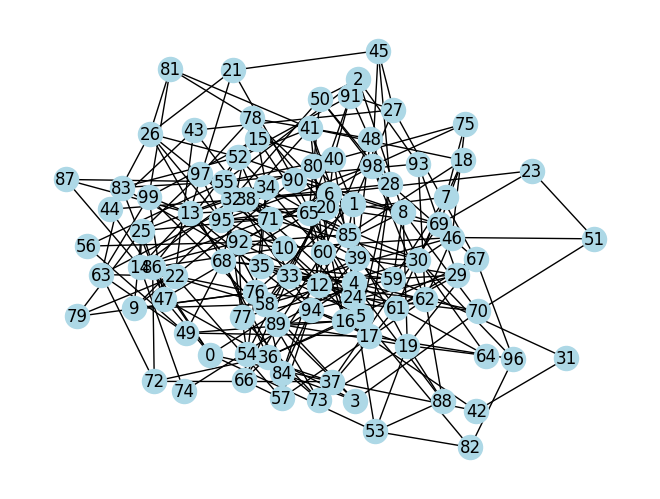

In [3]:
import matplotlib.pyplot as plt

# Ns= [100,1000,10000]
# for N in Ns:
N = 100
M = 3*N
edges = np.random.randint(0,N, size = (M,2)).tolist()
G  = nx.from_edgelist(edges)
nx.draw(G,with_labels=True,node_color="lightblue")
plt.show()  #?
# print(f"{asizeof.asizeof(G)/1e6} MB dla {N}")

In [4]:
from numba import njit

def f(x):
    for _ in range(1000000): x = x*3.9*(1-x)
    return x

g = njit(f)
g(0.2)
%timeit g(0.2)


2.66 ms ± 103 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [5]:
import random
def BA(N, m):
    adj = [[] for _ in range(m + 1)]
    repeated = []
    for i in range(m + 1):
        for j in range(i + 1, m + 1):
            adj[i].append(j)
            adj[j].append(i)
            repeated.extend([i, j])
    # Dodawanie kolejnych węzłów
    for i in range(m + 1, N):
        targets = set()
        while len(targets) < m:
            targets.add(random.choice(repeated))
        adj.append(list(targets))
        for j in targets:
            adj[j].append(i)
            repeated.extend([i, j])
    return adj


In [6]:
N = 1000000
siec = BA(N,3)


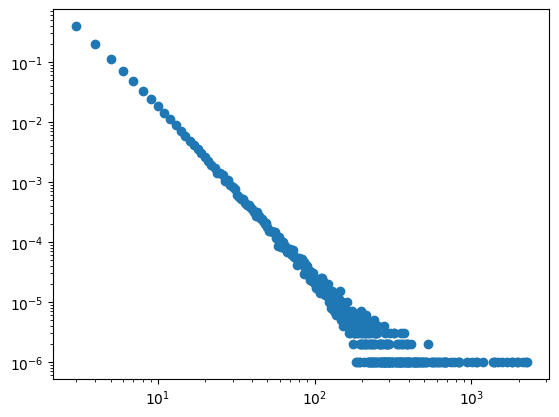

In [7]:
k = []
for wezel in siec:
    k.append(len(wezel))
vals,counts = np.unique(k,return_counts=True)
plt.loglog(vals,counts/N,'o')
plt.show()

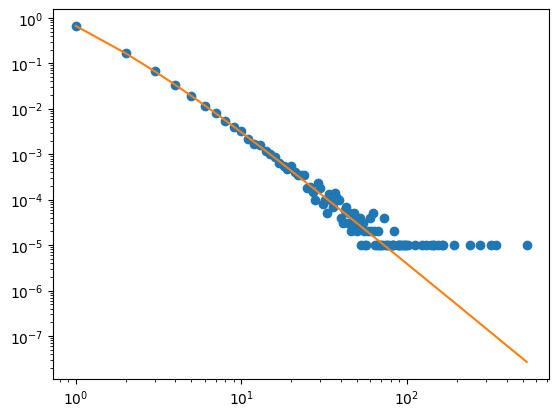

In [8]:
N = 100000
m = 1

siec = nx.barabasi_albert_graph(N,m)
k = np.array([d for _,d in  siec.degree()])
vals,counts = np.unique(k,return_counts = True)


P = (2*m*(m+1))/(vals*(vals+1)*(vals+2))
plt.loglog(vals,counts/N,'o')
plt.loglog(vals,P)

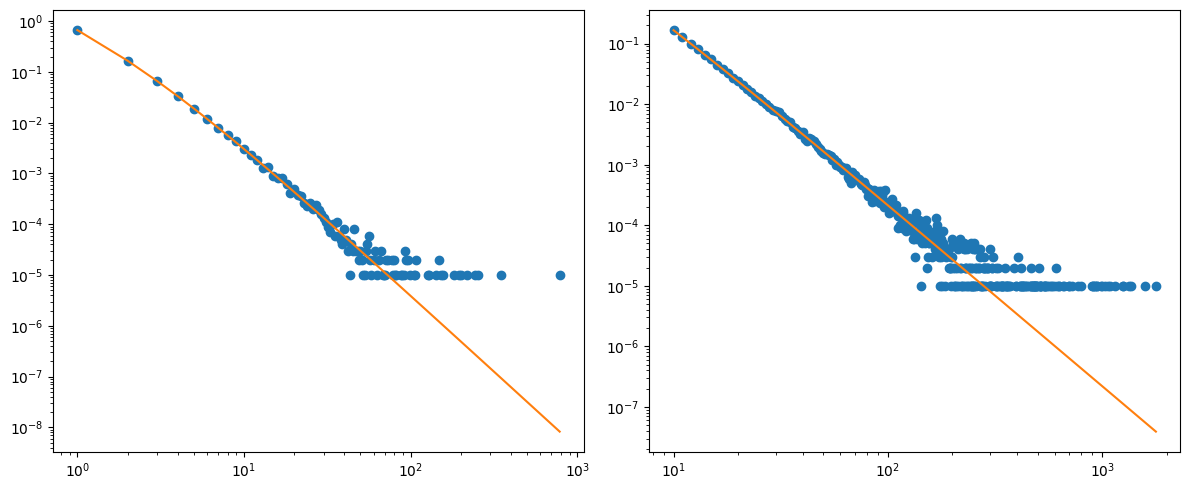

In [9]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

N = 100000
m_values = [1, 10]

# Tworzenie figury z dwoma podwykresami obok siebie
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, m in enumerate(m_values):
    siec = nx.barabasi_albert_graph(N, m)
    k = np.array([d for _, d in siec.degree()])
    vals, counts = np.unique(k, return_counts=True)
    
    # Teoretyczny rozkład stopni
    P = (2 * m * (m + 1)) / (vals * (vals + 1) * (vals + 2))
    
    # Wybór odpowiedniej osi dla danego m
    ax = axes[i]
    ax.loglog(vals, counts / N, 'o')
    ax.loglog(vals, P)
    


plt.tight_layout()
plt.show()

In [58]:
import random
def DMS(N, m,gamma):
    A = m*(gamma -3)
    adj = [[] for _ in range(m + 1)]
    repeated = []
    for i in range(m + 1):
        for j in range(i + 1, m + 1):
            adj[i].append(j)
            adj[j].append(i)
            repeated.extend([i, j])
    # Dodawanie kolejnych węzłów
    for i in range(m + 1, N):

        targets = set()
        while len(targets) < m:
            j = random.choice(repeated)
            k = len(adj[j])
            if np.random.rand() < (k+A)/k:
                targets.add(j)
        adj.append(list(targets))
        for j in targets:
            adj[j].append(i)
            repeated.extend([i, j])
    return adj


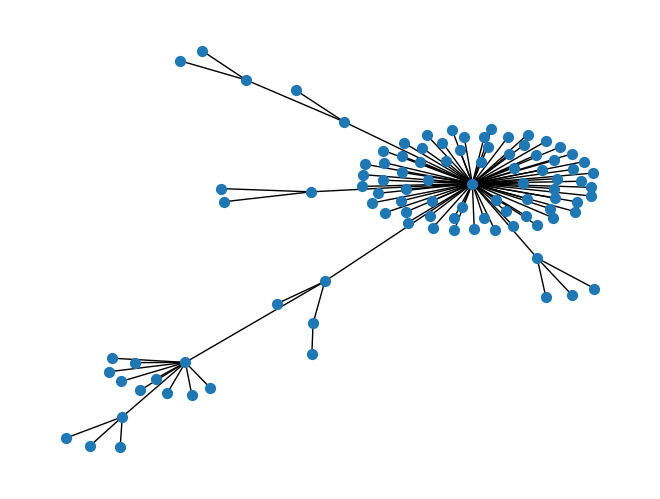

In [11]:
siec = DMS(100,1,2.1)
G  = nx.from_dict_of_lists(dict(enumerate(siec)))
nx.draw(G,node_size=50)

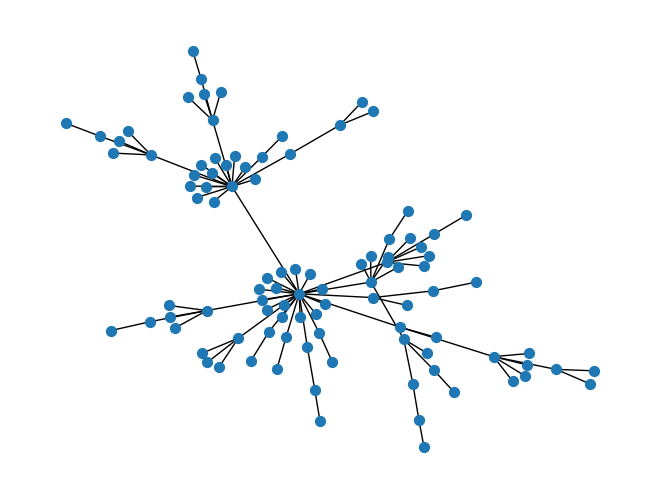

In [12]:
siec = DMS(100,1,3)
G  = nx.from_dict_of_lists(dict(enumerate(siec)))
nx.draw(G,node_size=50)

In [62]:
N = 100000
m = 3
gamma = 2.5

siec = DMS(N,m,gamma)
# k = np.array([d for _,d in  siec.degree()])
# vals,counts = np.unique(k,return_counts = True)


# P = (2*m*(m+1))/(vals*(vals+1)*(vals+2))
# plt.loglog(vals,counts/N,'o')
# plt.loglog(vals,P)

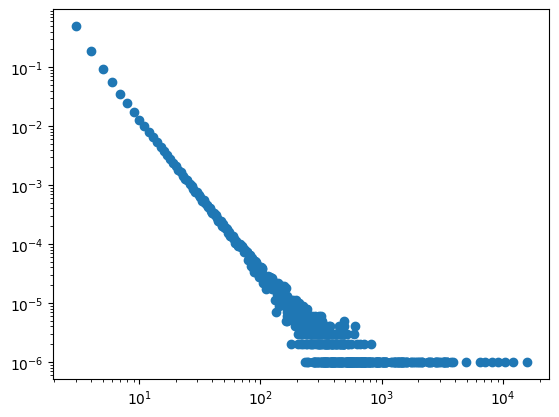

In [14]:
k = []
for wezel in siec:
    k.append(len(wezel))
vals,counts = np.unique(k,return_counts=True)
plt.loglog(vals,counts/N,'o')
plt.show()

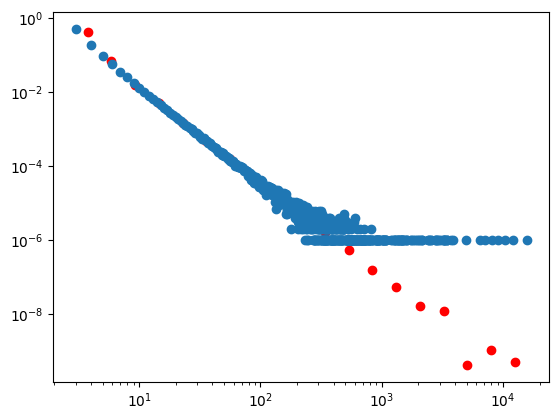

In [18]:
k = []
for wezel in siec:
    k.append(len(wezel))
vals,counts = np.unique(k,return_counts=True)
bins = np.geomspace(vals.min(),vals.max()+1,20)
n,__ = np.histogram(k, bins = bins)
centers = np.sqrt(bins[:-1]*bins[1:])
widths = np.diff(bins)
P_bin = n/(N*widths)
plt.loglog(centers,P_bin,'o',color = 'r')
plt.loglog(vals,counts/N,'o')
plt.show()

gamma = 2.5349640759477357


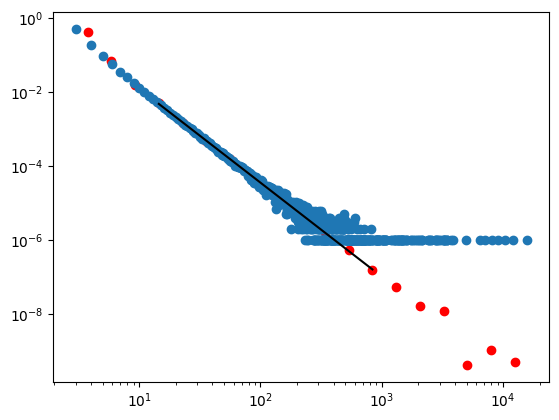

In [42]:
mask = (centers >=10) & (centers <=1000)
a,b = np.polyfit(np.log10(centers[mask]), np.log10(P_bin[mask]), 1)
print('gamma =', -a)


plt.loglog(centers,P_bin,'o',color = 'r')
plt.loglog(vals,counts/N,'o')
plt.loglog(centers[mask], 10**b * centers[mask]**a,color = 'black')
plt.show()

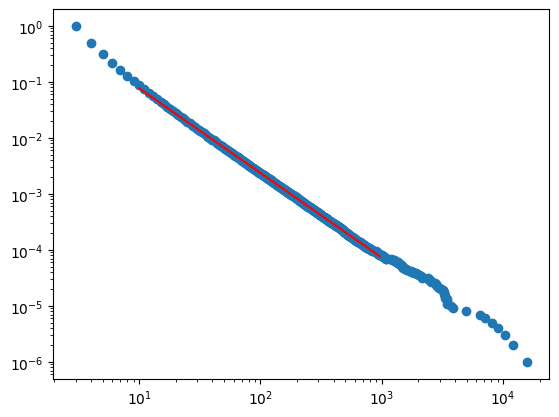

-1.5120989473847093 0.3972387268151773


In [ ]:
S = np.cumsum(counts[::-1])[::-1]/N
plt.loglog(vals, S, 'o')


mask = (vals >=10) & (vals <=1000)
a,b = np.polyfit(np.log10(vals[mask]), np.log10(S[mask]), 1)

plt.loglog(vals[mask],(vals[mask]**a)*10**b,color = 'red')
plt.show()
print(-a,b)


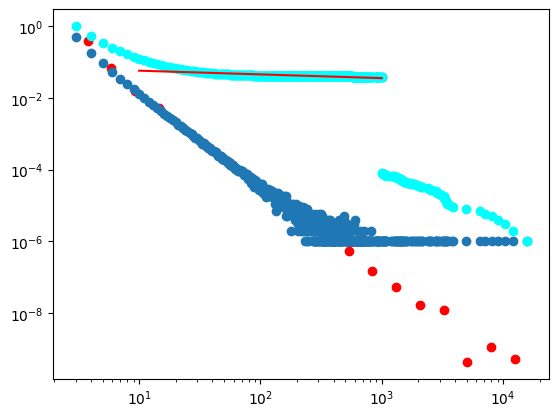

0.10391565680793004 -1.1296603021592386


In [ ]:
k = []
for wezel in siec:
    k.append(len(wezel))


k_perturbed = k +[1000]*40000
N2 = len(k_perturbed)


vals,counts = np.unique(k_perturbed,return_counts=True)
bins = np.geomspace(vals.min(),vals.max()+1,20)
n,__ = np.histogram(k, bins = bins)
centers = np.sqrt(bins[:-1]*bins[1:])
widths = np.diff(bins)
P_bin = n/(N*widths)
plt.loglog(centers,P_bin,'o',color = 'r')
plt.loglog(vals,counts/N,'o')




S = np.cumsum(counts[::-1])[::-1]/N
plt.loglog(vals, S, 'o',color = 'cyan')


mask = (vals >=10) & (vals <=1000)
a,b = np.polyfit(np.log10(vals[mask]), np.log10(S[mask]), 1)

plt.loglog(vals[mask],(vals[mask]**a)*10**b,color = 'red')
plt.show()


ValueError: operands could not be broadcast together with shapes (100000,) (234,) 

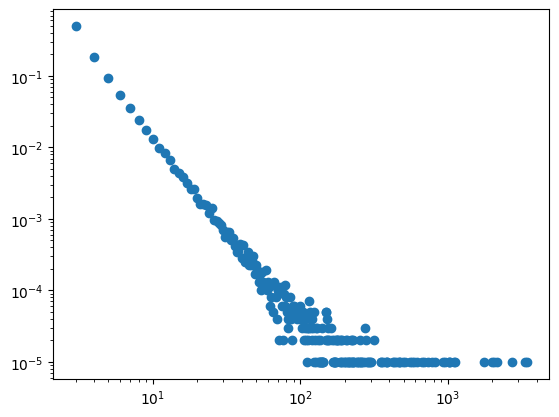

In [78]:
def DMS(N, m,gamma):
    A = m*(gamma -3)
    adj = [[] for _ in range(m + 1)]
    repeated = []
    for i in range(m + 1):
        for j in range(i + 1, m + 1):
            adj[i].append(j)
            adj[j].append(i)
            repeated.extend([i, j])
    # Dodawanie kolejnych węzłów
    for i in range(m + 1, N):

        targets = set()
        while len(targets) < m:
            j = random.choice(repeated)
            k = len(adj[j])
            if np.random.rand() < (k+A)/k:
                targets.add(j)
        adj.append(list(targets))
        for j in targets:
            adj[j].append(i)
            repeated.extend([i, j])
    return adj


k = []
for wezel in siec:
    k.append(len(wezel))
vals,counts = np.unique(k,return_counts=True)
bins = np.geomspace(vals.min(),vals.max()+1,20)
n,__ = np.histogram(k, bins = bins)
centers = np.sqrt(bins[:-1]*bins[1:])
widths = np.diff(bins)
P_bin = n/(N*widths)
# plt.loglog(centers,P_bin,'o',color = 'r')
plt.loglog(vals,counts/N,'o')


Q_k = (k*counts/100000)/np.mean(k)
plt.loglog(vals,Q_k,'o')
plt.show()